# E03 · 复杂道路车道检测（改进式 Notebook V1.1）
**V1.0 Baseline + V1.1 Improved Solution。** 保留原始二次曲线算法作为对照，增加自适应标线、RANSAC、三次曲线/自然样条、动态搜索与 Kalman 跟踪。  
CPU/OpenCV 即可运行，不训练模型。检测输出仍是几何候选；没有人工标注时，不将有效帧比例解释为准确率。

## 00 · 环境和真实视频素材
直道、普通弯道、复杂连续弯道素材均来自 Udacity CarND 项目；原始文件有 SHA256 校验。

In [1]:
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Video
from zipfile import ZipFile
# Local WSL/Jupyter/VS Code and Kaggle dataset layout.
def locate_e03():
    base=Path.cwd()
    for root in (base,base.parent,Path('/kaggle/input')):
        if not root.exists(): continue
        if (root/'images/01_solidWhiteRight_straight_white.jpg').is_file() and (root/'videos/E03_straight_input.mp4').is_file():return root
        if root == Path('/kaggle/input'):
            for file in root.glob('**/videos/E03_straight_input.mp4'):
                maybe=file.parent.parent
                if (maybe/'images/01_solidWhiteRight_straight_white.jpg').exists():return maybe
    raise FileNotFoundError('请完整解压 MVAI_E03_Lab.zip，确保 images/ 与 videos/ 位于 Notebook 同级')
DATA=locate_e03()
OUTPUT=Path.cwd()/'e03_outputs';OUTPUT.mkdir(exist_ok=True)
# Prefer actual installed CJK glyph fonts. Never suppress missing-glyph warnings:
# if no suitable font is installed (for example on Kaggle), use readable
# English captions while keeping the Notebook instructions in Chinese.
_candidates=('Noto Sans CJK SC','Source Han Sans SC','Microsoft YaHei',
             'SimHei','PingFang SC','WenQuanYi Micro Hei','Noto Sans CJK JP',
             'Noto Serif CJK JP')
_found={f.name for f in font_manager.fontManager.ttflist}
PLOT_CJK_FONT=next((f for f in _candidates if f in _found),None)
if PLOT_CJK_FONT:
    plt.rcParams['font.sans-serif']=[PLOT_CJK_FONT,'DejaVu Sans']
    plt.rcParams['axes.unicode_minus']=False
else:
    print('No CJK Matplotlib font: using readable English chart captions.')
def safe_caption(text):
    if PLOT_CJK_FONT:return text
    captions={
        '复杂连续弯道':'Complex curves','复杂弯道原图':'Complex curve input',
        '普通弯道':'Curved road','直道':'Straight road',
        '真实道路':'Original road','顶边宽度倍率':'Top-width scale',
        '顶边':'Top edge','鸟瞰掩膜':'Bird-eye mask','鸟瞰':'Bird-eye view',
        '原图':'Original','滑动窗口':'Sliding windows','候选':'candidates',
        '曲线':'curve','窗口数':'Windows',
        '强光/树影原图':'Glare/shadow input','组合掩膜':'Combined mask',
        '白线':'White line','黄线':'Yellow line','梯度':'gradient',
        '树影复杂场景':'Tree shadows','未增强':'Original mask',
        '拟合有效':'Fit valid', '无效':'Invalid',
    }
    for zh,en in captions.items():text=text.replace(zh,en)
    import re
    return re.sub(r'[㐀-鿿]+','',text).strip() or 'Road scene'
def read_image(name):
    img=cv2.imread(str(DATA/'images'/name))
    if img is None:raise FileNotFoundError(name)
    return cv2.resize(img,(640,360))
def panels(items,cols=3,size=(5.0,3.6)):
    # Four panels work better as a 2x2 grid on the student reading page.
    cols=2 if len(items)==4 else min(cols,3)
    rows=(len(items)+cols-1)//cols
    fig,axes=plt.subplots(rows,cols,figsize=(cols*size[0],rows*size[1]))
    for ax in np.atleast_1d(axes).ravel():ax.axis('off')
    for ax,(title,img) in zip(np.atleast_1d(axes).ravel(),items):
        ax.imshow(img if img.ndim==2 else cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
        ax.set_title(safe_caption(title),fontsize=12,pad=9)
        ax.axis('off')
    plt.tight_layout(pad=1.5);plt.show()
print('E03 DATA:',DATA,'OpenCV',cv2.__version__)

No CJK Matplotlib font: using readable English chart captions.
E03 DATA: /home/runner/work/multimodal-document-ai-learning-center/multimodal-document-ai-learning-center/docs/resources/course-labs/intelligent-perception OpenCV 5.1.0


In [2]:
"""E03 classroom-only classical lane-finding kernel, CPU/OpenCV; no learned model.
Returned lane curves are unlabelled geometry hypotheses, not ground truth.
"""
import cv2
import numpy as np
from dataclasses import dataclass

# Camera-dependent approximate road quadrilaterals; not physical calibration.
SCENE_QUADS = {
    'straight': (.43, .59, .09, .94, .60),
    'curve': (.42, .63, .06, .96, .61),
    'complex': (.40, .63, .03, .95, .61),
}

def resized(frame, size=(640, 360)):
    return cv2.resize(frame, size, interpolation=cv2.INTER_AREA)

def perspective(frame, scene='curve', top_shift=0., width_shift=0.):
    h,w=frame.shape[:2]
    left_top,right_top,left_bottom,right_bottom,y_top=SCENE_QUADS.get(scene,SCENE_QUADS['curve'])
    y_top=float(np.clip(y_top+top_shift,.42,.72))
    span=(right_top-left_top)*float(np.clip(1.+width_shift,.6,1.5))
    cx=(left_top+right_top)/2
    src=np.float32([[(cx-span/2)*w,y_top*h],[(cx+span/2)*w,y_top*h],
                    [right_bottom*w,.98*h],[left_bottom*w,.98*h]])
    dst=np.float32([[.23*w,0],[.77*w,0],[.77*w,h-1],[.23*w,h-1]])
    M=cv2.getPerspectiveTransform(src,dst)
    Minv=cv2.getPerspectiveTransform(dst,src)
    warped=cv2.warpPerspective(frame,M,(w,h))
    return warped,M,Minv,src

def e02_hough(frame, lo=50,hi=150,votes=25,length=35,gap=70,top=.55):
    """Reference to the approved E02 per-frame Canny→ROI→HoughLinesP route."""
    h,w=frame.shape[:2]
    gray=cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
    edges=cv2.Canny(cv2.GaussianBlur(gray,(5,5),1.2),lo,hi)
    mask=np.zeros_like(edges)
    poly=np.array([[(int(.05*w),int(.97*h)),(int(.42*w),int(top*h)),
                    (int(.58*w),int(top*h)),(int(.98*w),int(.97*h))]],np.int32)
    cv2.fillPoly(mask,poly,255)
    roi=cv2.bitwise_and(edges,mask)
    lines=cv2.HoughLinesP(roi,1,np.pi/180,threshold=votes,minLineLength=length,maxLineGap=gap)
    out=frame.copy()
    found=[] if lines is None else np.asarray(lines).reshape(-1,4).tolist()
    for x1,y1,x2,y2 in found:
        cv2.line(out,(x1,y1),(x2,y2),(30,220,30),2)
    return out,len(found),roi

def lane_masks(bgr,l_min=200,s_min=130,grad_min=45,clahe=False):
    if clahe:
        lab=cv2.cvtColor(bgr,cv2.COLOR_BGR2LAB)
        lab[:,:,0]=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(lab[:,:,0])
        bgr=cv2.cvtColor(lab,cv2.COLOR_LAB2BGR)
    hls=cv2.cvtColor(bgr,cv2.COLOR_BGR2HLS)
    h,l,s=cv2.split(hls)
    white=(l>=l_min)&(s<=175)
    yellow=(h>=12)&(h<=45)&(s>=s_min)&(l>=60)
    gx=cv2.Sobel(l,cv2.CV_32F,1,0,ksize=3)
    gx=cv2.convertScaleAbs(gx)
    gradient=(gx>=grad_min)&(l>=90)
    combo=((white|yellow)|(gradient & (l>115))).astype(np.uint8)*255
    k=cv2.getStructuringElement(cv2.MORPH_RECT,(3,3))
    combo=cv2.morphologyEx(combo,cv2.MORPH_CLOSE,k)
    return (white.astype(np.uint8)*255,yellow.astype(np.uint8)*255,
            gradient.astype(np.uint8)*255,combo)

def sliding_window(binary,nwindows=9,margin_frac=.10,minpix=35):
    h,w=binary.shape
    hist=np.sum((binary[h//2:]>0).astype(np.int32),axis=0)
    mid=w//2
    # Localize left and right within their respective halves; no semantic promise.
    left=int(np.argmax(hist[int(.05*w):mid])+int(.05*w))
    right=int(np.argmax(hist[mid:int(.95*w)])+mid)
    nony,nonx=np.nonzero(binary)
    width=max(1,h//int(nwindows))
    margin=max(8,int(margin_frac*w))
    left_ids=[];right_ids=[];boxes=[]
    for k in range(int(nwindows)):
        yhi=h-k*width; ylo=max(0,yhi-width)
        for side,center,collect in [('left',left,left_ids),('right',right,right_ids)]:
            xlo=max(0,center-margin);xhi=min(w,center+margin)
            ids=np.where((nony>=ylo)&(nony<yhi)&(nonx>=xlo)&(nonx<xhi))[0]
            collect.extend(ids.tolist())
            boxes.append((xlo,ylo,xhi,yhi,side))
            if len(ids)>minpix:
                if side=='left':left=int(np.mean(nonx[ids]))
                else:right=int(np.mean(nonx[ids]))
    return nonx,nony,np.asarray(left_ids,dtype=int),np.asarray(right_ids,dtype=int),boxes

def fit_lanes(binary,nwindows=9,margin_frac=.10,minpix=35):
    h,w=binary.shape
    xs,ys,left_ids,right_ids,boxes=sliding_window(binary,nwindows,margin_frac,minpix)
    result={'valid':False,'boxes':boxes,'left_pixels':len(left_ids),'right_pixels':len(right_ids)}
    if min(len(left_ids),len(right_ids))<max(60,2*minpix):return result
    if np.ptp(ys[left_ids])<.20*h or np.ptp(ys[right_ids])<.20*h:return result
    # Normalize y to improve polynomial stability.
    try:
        yl=ys[left_ids]/h; yr=ys[right_ids]/h
        lf=np.polyfit(yl,xs[left_ids],2);rf=np.polyfit(yr,xs[right_ids],2)
    except (np.linalg.LinAlgError,ValueError):return result
    probes=np.array([.38,.62,.91])
    lx=np.polyval(lf,probes);rx=np.polyval(rf,probes)
    widths=rx-lx
    # Soft guards are diagnostic: do not fabricate a line from insufficient data.
    if not np.all(np.isfinite(widths)) or not np.all((widths>.12*w)&(widths<.86*w)):
        return result
    result.update(valid=True,left=lf,right=rf,probes=probes,left_x=lx,right_x=rx)
    return result

@dataclass
class LaneTracker:
    alpha:float=.6
    max_missing:int=3
    last:object=None
    missing:int=0

    def update(self,d):
        if d.get('valid'):
            xy=np.stack([d['left_x'],d['right_x']])
            if self.last is not None and self.missing<=self.max_missing:
                # Accept real changes but suppress small instantaneous oscillations.
                xy=self.alpha*xy+(1-self.alpha)*self.last
            self.last=xy;self.missing=0
            return xy,'DETECTED'
        self.missing+=1
        if self.last is not None and self.missing<=self.max_missing:
            return self.last,'HISTORY (unverified)'
        self.last=None
        return None,'NO RELIABLE LANE'

def draw_curve(frame,Minv,fit,tracker=None,alpha=.6):
    out=frame.copy();h,w=frame.shape[:2]
    if tracker is None:tracker=LaneTracker(alpha=alpha,max_missing=0)
    xy,status=tracker.update(fit)
    if xy is None:
        cv2.putText(out,status,(12,30),cv2.FONT_HERSHEY_SIMPLEX,.65,(25,25,235),2)
        return out,status,None
    # Reconstruct a quadratic from 3 normalized-y probe positions per boundary.
    y=fit.get('probes',np.array([.38,.62,.91]))
    lc=np.polyfit(y,xy[0],2);rc=np.polyfit(y,xy[1],2)
    yt=np.linspace(.32,.98,50)
    left=np.column_stack([np.polyval(lc,yt),yt*h]).astype(np.float32)
    right=np.column_stack([np.polyval(rc,yt),yt*h]).astype(np.float32)
    polygon=np.concatenate([left,right[::-1]])
    warped_poly=cv2.perspectiveTransform(polygon.reshape(-1,1,2),Minv).reshape(-1,2)
    pts=np.round(warped_poly).astype(np.int32)
    mask=np.zeros_like(out);cv2.fillPoly(mask,[pts],(55,180,35))
    out=cv2.addWeighted(out,1.,mask,.23,0)
    borders=cv2.perspectiveTransform(np.stack([left,right]).reshape(-1,1,2),Minv).reshape(2,-1,2)
    for line,color in zip(borders,[(255,170,20),(20,220,255)]):
        cv2.polylines(out,[np.round(line).astype(np.int32)],False,color,4,cv2.LINE_AA)
    cv2.putText(out,status,(12,30),cv2.FONT_HERSHEY_SIMPLEX,.54,(255,255,255),2)
    return out,status,float(np.mean(xy[:,2]))

def e03_detect(frame,scene='curve',tracker=None,top_shift=0.,width_shift=0.,
               nwindows=9,margin_frac=.10,l_min=200,s_min=130,clahe=False):
    bird,M,Minv,src=perspective(frame,scene,top_shift,width_shift)
    wm,ym,gm,binary=lane_masks(bird,l_min,s_min,clahe=clahe)
    h,w=binary.shape
    binary[:int(.08*h)]=0
    fit=fit_lanes(binary,nwindows,margin_frac)
    overlay,status,bottom=draw_curve(frame,Minv,fit,tracker)
    fit['status']=status;fit['bottom_x']=bottom
    return overlay,fit,{'bird':bird,'mask':binary,'white':wm,'yellow':ym,'grad':gm,'src':src,'Minv':Minv.astype(float).tolist(),'probes':fit.get('probes',np.array([.38,.62,.91])).astype(float).tolist()}

In [3]:
"""E03 V1.1 robust lane fitting for classroom comparison.

CPU/OpenCV only. This module is intentionally independent from the V1.0
baseline. It uses adaptive color/gradient candidates, prior-guided search,
RANSAC polynomial inliers, natural cubic splines and a per-anchor Kalman
tracker. Returned curves remain hypotheses unless compared with manual labels.
"""
from dataclasses import dataclass
import cv2
import numpy as np

SCENE_QUADS = {
    "straight": (.43, .59, .09, .94, .60),
    "curve": (.42, .63, .06, .96, .61),
    "complex": (.40, .63, .03, .95, .61),
}
CURVE_Y = np.linspace(.30, .97, 18, dtype=np.float64)
PROBE_Y = np.array([.38, .62, .91], dtype=np.float64)


def improved_perspective(frame, scene="curve"):
    """Use the same approximate scene quadrilaterals as V1.0."""
    h, w = frame.shape[:2]
    lt, rt, lb, rb, yt = SCENE_QUADS.get(scene, SCENE_QUADS["curve"])
    src = np.float32([[lt*w, yt*h], [rt*w, yt*h],
                      [rb*w, .98*h], [lb*w, .98*h]])
    dst = np.float32([[.23*w, 0], [.77*w, 0],
                      [.77*w, h-1], [.23*w, h-1]])
    matrix = cv2.getPerspectiveTransform(src, dst)
    inverse = cv2.getPerspectiveTransform(dst, src)
    bird = cv2.warpPerspective(frame, matrix, (w, h))
    return bird, matrix, inverse, src


def adaptive_lane_mask(bgr, clahe=True):
    """Combine local lightness, yellow hue and horizontal gradients."""
    hls = cv2.cvtColor(bgr, cv2.COLOR_BGR2HLS)
    hue, light, sat = cv2.split(hls)
    if clahe:
        light = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(light)
    white_global = (light >= 148) & (sat <= 178)
    local = cv2.adaptiveThreshold(
        light, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, 31, -8
    ) > 0
    white_local = local & (light >= 105) & (sat <= 185)
    yellow = (hue >= 12) & (hue <= 45) & (sat >= 55) & (light >= 52)
    gx = cv2.Sobel(light, cv2.CV_32F, 1, 0, ksize=3)
    gx = cv2.convertScaleAbs(gx)
    gradient = (gx >= 42) & (light >= 112) & (sat <= 175)
    mask = (white_global | white_local | yellow | gradient).astype(np.uint8) * 255
    h, w = mask.shape
    road_roi = np.zeros_like(mask)
    polygon = np.array([[
        (int(.02*w), int(.98*h)), (int(.12*w), int(.05*h)),
        (int(.88*w), int(.05*h)), (int(.98*w), int(.98*h))
    ]], dtype=np.int32)
    cv2.fillPoly(road_roi, polygon, 255)
    mask = cv2.bitwise_and(mask, road_roi)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    clean = np.zeros_like(mask)
    for i in range(1, count):
        if stats[i, cv2.CC_STAT_AREA] >= 7:
            clean[labels == i] = 255
    return clean


def _window_search(binary, nwindows=10, margin=72, minpix=24):
    h, w = binary.shape
    histogram = np.sum(binary[h//2:, :] > 0, axis=0)
    mid = w // 2
    left = int(np.argmax(histogram[int(.04*w):mid]) + int(.04*w))
    right = int(np.argmax(histogram[mid:int(.96*w)]) + mid)
    ys, xs = np.nonzero(binary)
    step = max(1, h // int(nwindows))
    points = [[], []]
    boxes = []
    centers = [left, right]
    for k in range(int(nwindows)):
        y_hi = h - k*step
        y_lo = max(0, y_hi-step)
        for side in (0, 1):
            center = centers[side]
            x_lo = max(0, center-margin)
            x_hi = min(w, center+margin)
            ids = np.where((ys >= y_lo) & (ys < y_hi) &
                           (xs >= x_lo) & (xs < x_hi))[0]
            if ids.size:
                points[side].extend(np.column_stack([xs[ids], ys[ids]]).tolist())
            boxes.append((x_lo, y_lo, x_hi, y_hi, side))
            if ids.size > minpix:
                centers[side] = int(np.mean(xs[ids]))
    return [np.asarray(p, dtype=np.float64).reshape(-1, 2) for p in points], boxes


def _prior_search(binary, prior, margin=58):
    h, w = binary.shape
    ys, xs = np.nonzero(binary)
    if prior is None or ys.size == 0:
        return None
    if isinstance(prior, dict):
        curve_y = np.asarray(prior.get("curve_y", CURVE_Y), dtype=np.float64)
        left_x = np.asarray(prior.get("left_x", []), dtype=np.float64)
        right_x = np.asarray(prior.get("right_x", []), dtype=np.float64)
    else:
        samples = np.asarray(prior, dtype=np.float64)
        if samples.ndim != 2 or samples.shape[0] != 2:
            return None
        curve_y = CURVE_Y
        left_x, right_x = samples[0], samples[1]
    if left_x.size != curve_y.size or right_x.size != curve_y.size:
        return None
    y_norm = ys / float(h)
    points = []
    for expected in (left_x, right_x):
        predicted = np.interp(y_norm, curve_y, expected)
        selected = np.abs(xs - predicted) <= margin
        pts = np.column_stack([xs[selected], ys[selected]]).astype(np.float64)
        if pts.shape[0] < 55 or np.ptp(pts[:, 1]) < .22*h:
            return None
        points.append(pts)
    return points


def ransac_polynomial(points, degree=3, threshold=15.0, iterations=70,
                      min_inliers=65, seed=17):
    """Fit x(y) robustly; return coefficients, full-size inlier mask and ratio."""
    all_points = np.asarray(points, dtype=np.float64).reshape(-1, 2)
    if all_points.shape[0] < max(min_inliers, degree+1):
        return None, None, 0.0
    rng = np.random.default_rng(seed)
    if all_points.shape[0] > 1800:
        sample_ids = rng.choice(all_points.shape[0], 1800, replace=False)
        pts = all_points[sample_ids]
    else:
        pts = all_points
    x = pts[:, 0]
    y_scale = max(1.0, float(np.max(all_points[:, 1]) + 1))
    y = pts[:, 1] / y_scale
    best = None
    best_count = 0
    best_error = float("inf")
    sample_size = degree + 1
    for _ in range(int(iterations)):
        ids = rng.choice(len(pts), sample_size, replace=False)
        if np.ptp(y[ids]) < .16:
            continue
        try:
            coeff = np.polyfit(y[ids], x[ids], degree)
        except (ValueError, np.linalg.LinAlgError, FloatingPointError):
            continue
        residual = np.abs(x - np.polyval(coeff, y))
        inliers = residual <= threshold
        count = int(np.count_nonzero(inliers))
        if count < min_inliers:
            continue
        error = float(np.median(residual[inliers]))
        if count > best_count or (count == best_count and error < best_error):
            best, best_count, best_error = inliers, count, error
    if best is None:
        return None, None, 0.0
    try:
        provisional = np.polyfit(y[best], x[best], degree)
        full_y = all_points[:, 1] / y_scale
        full_inliers = np.abs(all_points[:, 0] - np.polyval(provisional, full_y)) <= threshold
        if np.count_nonzero(full_inliers) < min_inliers:
            return None, None, 0.0
        coeff = np.polyfit(full_y[full_inliers], all_points[full_inliers, 0], degree)
    except (ValueError, np.linalg.LinAlgError, FloatingPointError):
        return None, None, 0.0
    return coeff, full_inliers, float(np.count_nonzero(full_inliers) / len(all_points))

def natural_spline_fit(points, bins=14):
    """Robust natural cubic spline from the dominant x-cluster in each y band."""
    pts = np.asarray(points, dtype=np.float64).reshape(-1, 2)
    if pts.shape[0] < 30:
        return None
    y = pts[:, 1] / max(1.0, float(np.max(pts[:, 1]) + 1))
    x = pts[:, 0]
    edges = np.linspace(.27, .995, bins+1)
    nodes_y, nodes_x = [], []
    x_edges = np.arange(0, 649, 8)
    for lo, hi in zip(edges[:-1], edges[1:]):
        band = (y >= lo) & (y < hi)
        if np.count_nonzero(band) < 8:
            continue
        values = x[band]
        hist, bins_x = np.histogram(values, bins=x_edges)
        if hist.size == 0 or int(hist.max()) < 3:
            continue
        peak = int(np.argmax(hist))
        center = (bins_x[peak] + bins_x[peak+1]) / 2.0
        cluster = band & (np.abs(x-center) <= 14.0)
        if np.count_nonzero(cluster) >= 5:
            nodes_y.append(float(np.median(y[cluster])))
            nodes_x.append(float(np.median(x[cluster])))
    if len(nodes_y) < 5:
        return None
    order = np.argsort(nodes_y)
    nodes_y = np.asarray(nodes_y, dtype=np.float64)[order]
    nodes_x = np.asarray(nodes_x, dtype=np.float64)[order]
    # Merge duplicate/near-duplicate y nodes to keep the spline system stable.
    keep = np.r_[True, np.diff(nodes_y) > 1e-4]
    nodes_y, nodes_x = nodes_y[keep], nodes_x[keep]
    if len(nodes_y) < 5:
        return None
    h = np.diff(nodes_y)
    n = len(nodes_y)
    matrix = np.zeros((n, n), dtype=np.float64)
    rhs = np.zeros(n, dtype=np.float64)
    matrix[0, 0] = matrix[-1, -1] = 1.0
    for i in range(1, n-1):
        matrix[i, i-1] = h[i-1]
        matrix[i, i] = 2.0*(h[i-1]+h[i])
        matrix[i, i+1] = h[i]
        rhs[i] = 6.0*((nodes_x[i+1]-nodes_x[i])/h[i] -
                      (nodes_x[i]-nodes_x[i-1])/h[i-1])
    try:
        second = np.linalg.solve(matrix, rhs)
    except np.linalg.LinAlgError:
        return None
    return {"y": nodes_y, "x": nodes_x, "second": second}

def evaluate_spline(model, query):
    q = np.asarray(query, dtype=np.float64)
    y, x, second = model["y"], model["x"], model["second"]
    q = np.clip(q, y[0], y[-1])
    idx = np.clip(np.searchsorted(y, q, side="right")-1, 0, len(y)-2)
    width = y[idx+1]-y[idx]
    a = (y[idx+1]-q)/width
    b = (q-y[idx])/width
    return (a*x[idx] + b*x[idx+1] +
            ((a**3-a)*second[idx] + (b**3-b)*second[idx+1]) *
            (width**2)/6.0)


def fit_curve_model(points, model="spline", seed=17):
    if model == "spline":
        pts = np.asarray(points, dtype=np.float64).reshape(-1, 2)
        spline = natural_spline_fit(pts)
        if spline is None:
            return None, 0.0
        y_all = pts[:, 1] / max(1.0, float(np.max(pts[:, 1]) + 1))
        residual = np.abs(pts[:, 0] - evaluate_spline(spline, y_all))
        inliers = residual <= 18.0
        if np.count_nonzero(inliers) < 65:
            return None, 0.0
        refined = natural_spline_fit(pts[inliers])
        if refined is None:
            return None, 0.0
        return ("spline", refined), float(np.count_nonzero(inliers)/len(pts))
    degree = 2 if model == "quadratic" else 3
    coeff, inliers, ratio = ransac_polynomial(
        points, degree=degree, threshold=15.0, iterations=75,
        min_inliers=65, seed=seed
    )
    if coeff is None:
        return None, 0.0
    return ("poly", coeff), ratio

def evaluate_model(fitted, y_values):
    kind, payload = fitted
    y_values = np.asarray(y_values, dtype=np.float64)
    if kind == "spline":
        return evaluate_spline(payload, y_values)
    return np.polyval(payload, y_values)


def fit_pair_from_points(points, model="spline", seed=17):
    left, left_ratio = fit_curve_model(points[0], model, seed)
    right, right_ratio = fit_curve_model(points[1], model, seed+1)
    if left is None or right is None:
        return None
    left_values = evaluate_model(left, CURVE_Y)
    right_values = evaluate_model(right, CURVE_Y)
    widths = right_values-left_values
    if (not np.all(np.isfinite(widths)) or
            not np.all((widths > 0.12*640) & (widths < 0.86*640))):
        return None
    if np.ptp(widths) > .48*640:
        return None
    return {
        "valid": True, "curve_y": CURVE_Y.copy(),
        "left_curve_x": left_values, "right_curve_x": right_values,
        "left_x": np.interp(PROBE_Y, CURVE_Y, left_values),
        "right_x": np.interp(PROBE_Y, CURVE_Y, right_values),
        "inlier_ratio": float((left_ratio+right_ratio)/2),
        "model": model,
    }


def fit_mask(binary, model="spline", prior=None, margin=58, nwindows=10):
    points = _prior_search(binary, prior, margin=margin)
    search_mode = "prior" if points is not None else "sliding"
    boxes = []
    if points is None:
        points, boxes = _window_search(binary, nwindows=nwindows, margin=72)
    fit = fit_pair_from_points(points, model=model)
    if fit is None:
        return {"valid": False, "search_mode": search_mode,
                "left_points": len(points[0]), "right_points": len(points[1]),
                "boxes": boxes}
    fit.update(search_mode=search_mode, left_points=len(points[0]),
               right_points=len(points[1]), boxes=boxes)
    return fit


class LaneKalmanTracker:
    """Independent constant-velocity Kalman filter for each curve anchor."""
    def __init__(self, max_missing=4, gate_px=105.0):
        self.max_missing = int(max_missing)
        self.gate_px = float(gate_px)
        self.filters = None
        self.missing = 0
        self.last_samples = None

    @staticmethod
    def _new_filter(value):
        kf = cv2.KalmanFilter(2, 1, 0, cv2.CV_32F)
        kf.transitionMatrix = np.array([[1, 1], [0, 1]], dtype=np.float32)
        kf.measurementMatrix = np.array([[1, 0]], dtype=np.float32)
        kf.processNoiseCov = np.eye(2, dtype=np.float32) * 0.035
        kf.measurementNoiseCov = np.array([[18.0]], dtype=np.float32)
        kf.errorCovPost = np.eye(2, dtype=np.float32) * 25.0
        kf.statePost = np.array([[value], [0.0]], dtype=np.float32)
        return kf

    def reset(self):
        self.filters = None
        self.missing = 0
        self.last_samples = None

    def update(self, fit):
        valid = bool(fit and fit.get("valid"))
        if self.filters is None:
            if not valid:
                return None, "NO RELIABLE LANE"
            values = np.concatenate([fit["left_curve_x"], fit["right_curve_x"]])
            self.filters = [self._new_filter(float(v)) for v in values]
            self.last_samples = values.reshape(2, -1).copy()
            self.missing = 0
            return self.last_samples.copy(), "DETECTED · KALMAN INIT"

        predicted = []
        for kf in self.filters:
            state = kf.predict()
            predicted.append(float(state[0, 0]))
        predicted = np.asarray(predicted, dtype=np.float64)
        if valid:
            measured = np.concatenate([fit["left_curve_x"], fit["right_curve_x"]])
            residual = np.abs(measured-predicted)
            if self.missing >= self.max_missing or np.count_nonzero(residual <= self.gate_px) < len(measured)*.55:
                self.filters = [self._new_filter(float(v)) for v in measured]
                result = measured.copy()
                status = "DETECTED · KALMAN REACQUIRED"
            else:
                result = predicted.copy()
                for i, (kf, value) in enumerate(zip(self.filters, measured)):
                    if residual[i] <= self.gate_px:
                        corrected = kf.correct(np.array([[value]], dtype=np.float32))
                        result[i] = float(corrected[0, 0])
                    else:
                        kf.statePost = kf.statePre.copy()
                        kf.errorCovPost = kf.errorCovPre.copy()
                status = "DETECTED · KALMAN"
            self.missing = 0
        else:
            self.missing += 1
            result = predicted.copy()
            for kf in self.filters:
                kf.statePost = kf.statePre.copy()
                kf.errorCovPost = kf.errorCovPre.copy()
            if self.missing > self.max_missing:
                self.reset()
                return None, "NO RELIABLE LANE"
            status = "KALMAN PREDICTED · UNVERIFIED"
        self.last_samples = result.reshape(2, -1).copy()
        return self.last_samples.copy(), status


def draw_improved_overlay(frame, inverse, curve_y, left_x, right_x, status):
    out = frame.copy()
    if left_x is None or right_x is None:
        cv2.putText(out, status, (12, 30), cv2.FONT_HERSHEY_SIMPLEX,
                    .58, (25, 25, 235), 2, cv2.LINE_AA)
        return out
    h, w = frame.shape[:2]
    left = np.column_stack([left_x, curve_y*h]).astype(np.float32)
    right = np.column_stack([right_x, curve_y*h]).astype(np.float32)
    left_src = cv2.perspectiveTransform(left.reshape(-1, 1, 2), inverse).reshape(-1, 2)
    right_src = cv2.perspectiveTransform(right.reshape(-1, 1, 2), inverse).reshape(-1, 2)
    left_src[:, 0] = np.clip(left_src[:, 0], 0, w-1)
    left_src[:, 1] = np.clip(left_src[:, 1], 0, h-1)
    right_src[:, 0] = np.clip(right_src[:, 0], 0, w-1)
    right_src[:, 1] = np.clip(right_src[:, 1], 0, h-1)
    polygon = np.vstack([left_src, right_src[::-1]])
    mask = np.zeros_like(out)
    cv2.fillPoly(mask, [np.round(polygon).astype(np.int32)], (55, 180, 35))
    out = cv2.addWeighted(out, 1.0, mask, .23, 0)
    color = (40, 190, 255) if "PREDICTED" in status else (20, 220, 255)
    cv2.polylines(out, [np.round(left_src).astype(np.int32)], False, (255, 170, 20), 3, cv2.LINE_AA)
    cv2.polylines(out, [np.round(right_src).astype(np.int32)], False, color, 3, cv2.LINE_AA)
    cv2.putText(out, status, (12, 28), cv2.FONT_HERSHEY_SIMPLEX,
                .50, (255, 255, 255), 2, cv2.LINE_AA)
    return out


def e03_improved_detect(frame, scene="curve", tracker=None, model="spline",
                        margin=58, clahe=True):
    """V1.1 pipeline. Pass one tracker through frames in chronological order."""
    bird, matrix, inverse, src = improved_perspective(frame, scene)
    mask = adaptive_lane_mask(bird, clahe=clahe)
    prior = tracker.last_samples if tracker is not None else None
    fit = fit_mask(mask, model=model, prior=prior, margin=margin)
    samples, status = tracker.update(fit) if tracker is not None else (
        (np.stack([fit["left_curve_x"], fit["right_curve_x"]]), "DETECTED")
        if fit.get("valid") else (None, "NO RELIABLE LANE")
    )
    if samples is None:
        left_curve_x = right_curve_x = None
    else:
        left_curve_x, right_curve_x = samples[0], samples[1]
    overlay = draw_improved_overlay(frame, inverse, CURVE_Y,
                                    left_curve_x, right_curve_x, status)
    result = dict(fit)
    result.update({
        "valid": bool(fit.get("valid")),
        "status": status,
        "curve_y": CURVE_Y.tolist(),
        "left_curve_x": None if left_curve_x is None else left_curve_x.tolist(),
        "right_curve_x": None if right_curve_x is None else right_curve_x.tolist(),
        "left_x": None if left_curve_x is None else np.interp(PROBE_Y, CURVE_Y, left_curve_x).tolist(),
        "right_x": None if right_curve_x is None else np.interp(PROBE_Y, CURVE_Y, right_curve_x).tolist(),
        "bottom_x": None if left_curve_x is None else float((left_curve_x[-1]+right_curve_x[-1])/2),
        "display_valid": samples is not None,
    })
    return overlay, result, {
        "bird": bird, "mask": mask, "matrix": matrix, "inverse": inverse,
        "src": src, "curve_y": CURVE_Y.tolist(),
    }


## 01 · 探索一：道路透视与鸟瞰变换
**先预测：** 改变透视梯形顶部高度，会保留更多道路还是引入更多非车道区域？
1. 固定顶边宽度，仅比较顶边高度比例 0.50 / 0.56 / 0.62。
2. 固定高度，再比较顶边宽度；换到急弯观察裁剪失效。
3. 思考：鸟瞰图是否等于经过相机标定的真实地面几何？

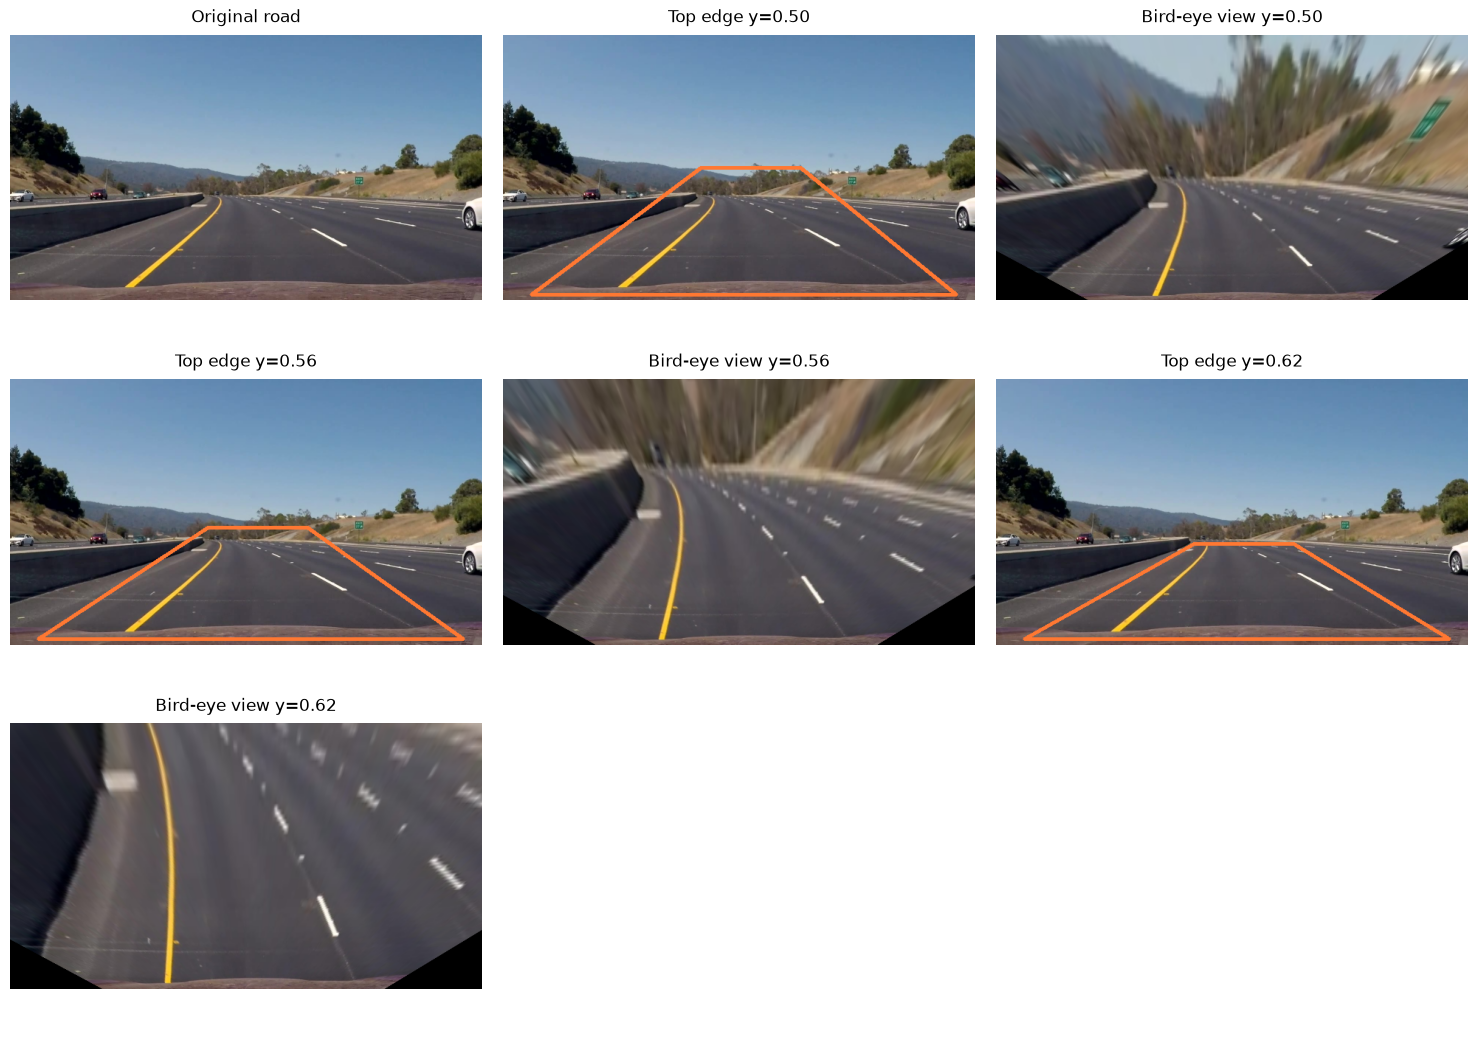

In [4]:
img=read_image('03_project_curve_intro.jpg')
results=[('真实道路',img)]
for shift in (-.11,-.05,.01):
    bird,M,Minv,src=perspective(img,'curve',top_shift=shift)
    draw=img.copy();cv2.polylines(draw,[np.int32(src)],True,(50,120,255),3)
    results.extend([(f'顶边 y={.61+shift:.2f}',draw),(f'鸟瞰 y={.61+shift:.2f}',bird)])
panels(results,cols=4)

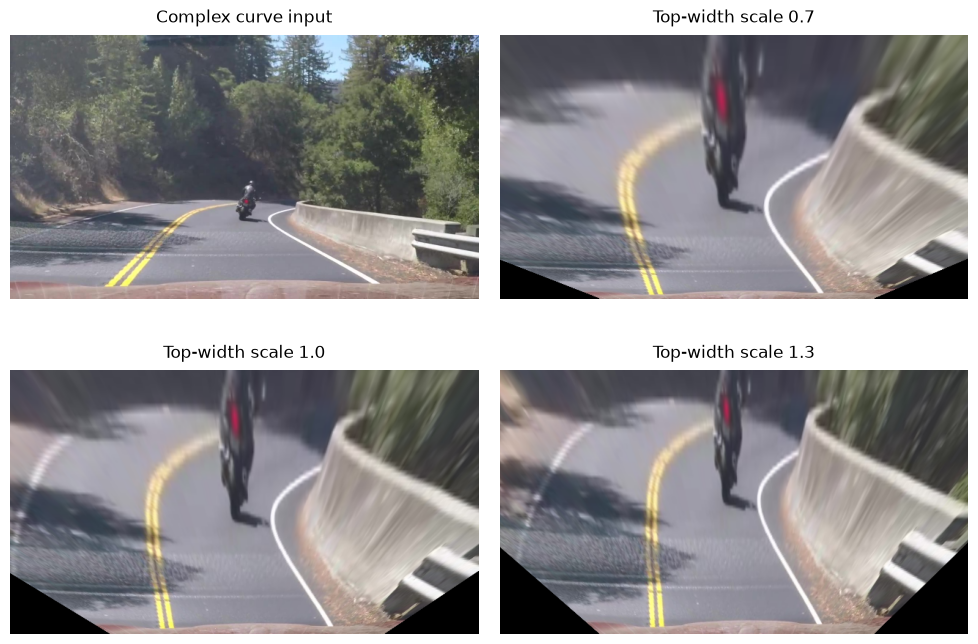

In [5]:
img=read_image('07_harder_curve_motorcycle.jpg')
panels([('复杂弯道原图',img)]+[(f'顶边宽度倍率 {1+x:.1f}',perspective(img,'complex',width_shift=x)[0]) for x in (-.3,0,.3)],cols=4)

## 02 · 探索二：从 Hough 直线到曲线拟合
**先预测：** 将滑动窗口加宽，能否避免急弯漏检？会不会同时抓到护栏和阴影？
1. 对比 E02 Hough、鸟瞰掩膜、滑动窗口与二次曲线。
2. 只修改窗口数量 6 / 9 / 12，比较候选像素和有效性。
3. 解释二次曲线、分段曲线与连续 S 形转向的关系；拟合平滑不代表检测正确。

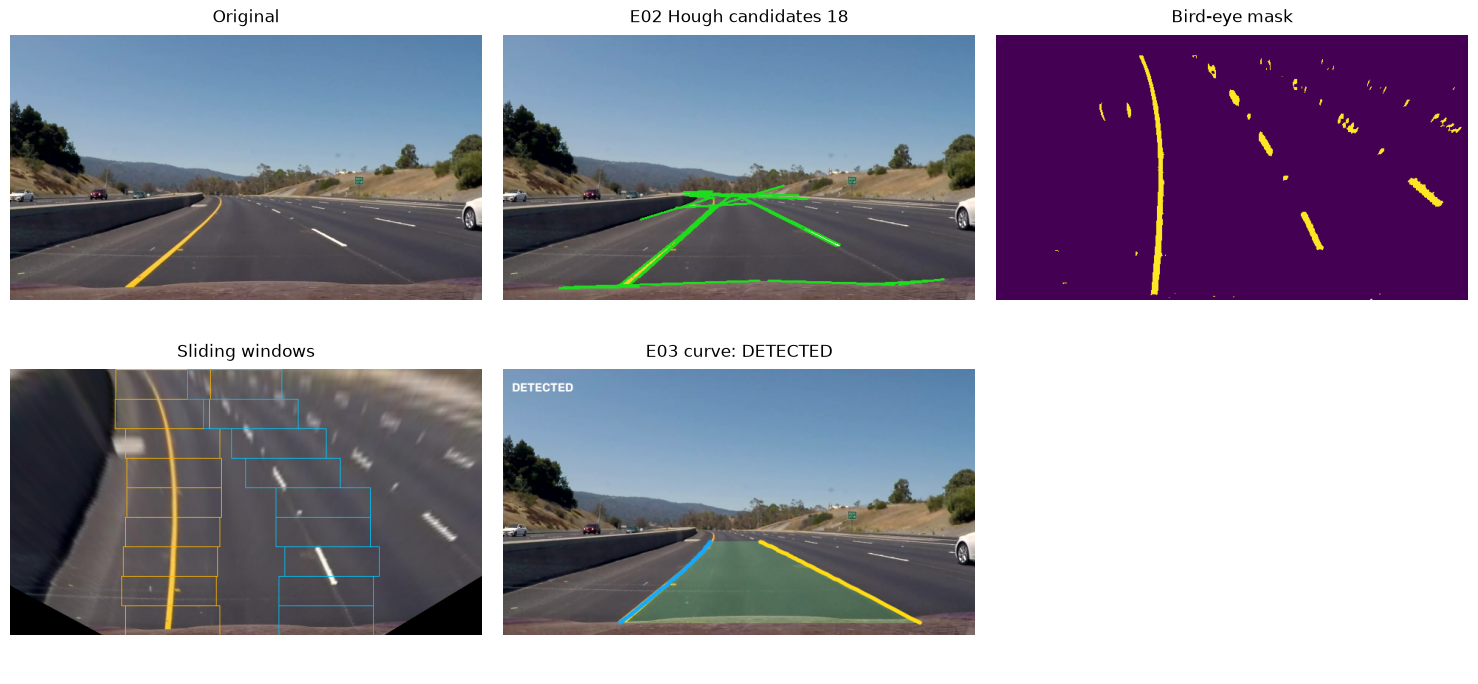

候选像素 (左/右): 2445 1174 拟合有效: True


In [6]:
img=read_image('03_project_curve_intro.jpg')
e02,n,roi=e02_hough(img)
e03,fit,steps=e03_detect(img,'curve')
search=steps['bird'].copy()
for x1,y1,x2,y2,side in fit['boxes']:
    cv2.rectangle(search,(x1,y1),(x2,y2),(0,180,255) if side=='left' else (255,200,0),1)
panels([('原图',img),(f'E02 Hough 候选 {n}',e02),('鸟瞰掩膜',steps['mask']),('滑动窗口',search),(f'E03 曲线: {fit["status"]}',e03)],cols=3)
print('候选像素 (左/右):',fit['left_pixels'],fit['right_pixels'],'拟合有效:',fit['valid'])

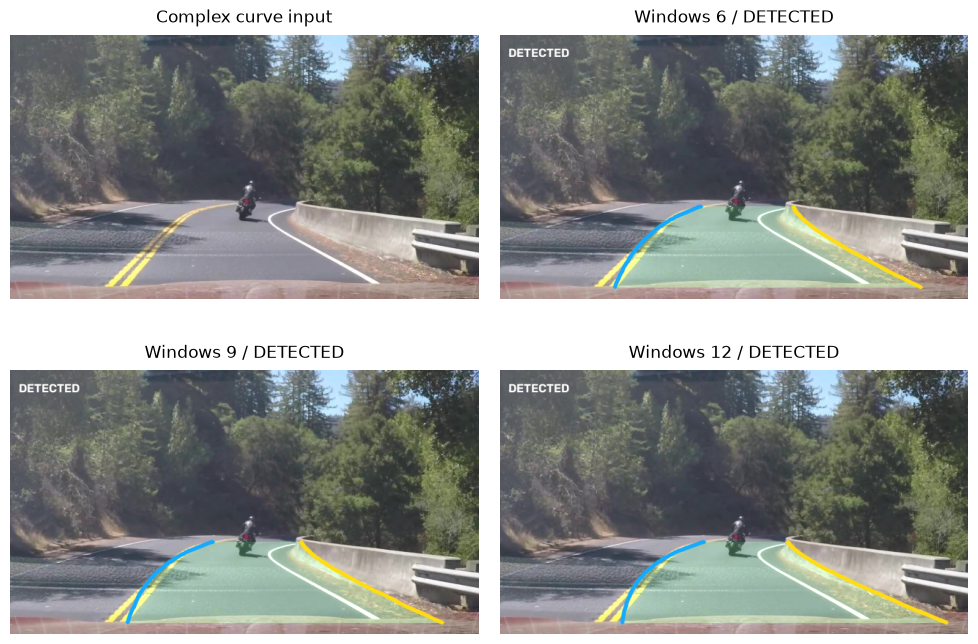

In [7]:
img=read_image('07_harder_curve_motorcycle.jpg')
results=[('复杂弯道原图',img)]
for nw in (6,9,12):
    out,fit,_=e03_detect(img,'complex',nwindows=nw)
    results.append((f'窗口数 {nw} / {fit["status"]}',out))
panels(results,cols=4)

## 03 · 探索三：阴影、强光与标线提取
**先预测：** 降低亮度阈值一定能找回阴影里的白线吗？
1. 在同一图上仅修改 HLS 白线亮度阈值 170 / 200 / 230。
2. 比较黄色掩膜、Sobel 梯度和组合掩膜；观察树影和路面反光。
3. 尝试 CLAHE，讨论增加纹理噪声的副作用。

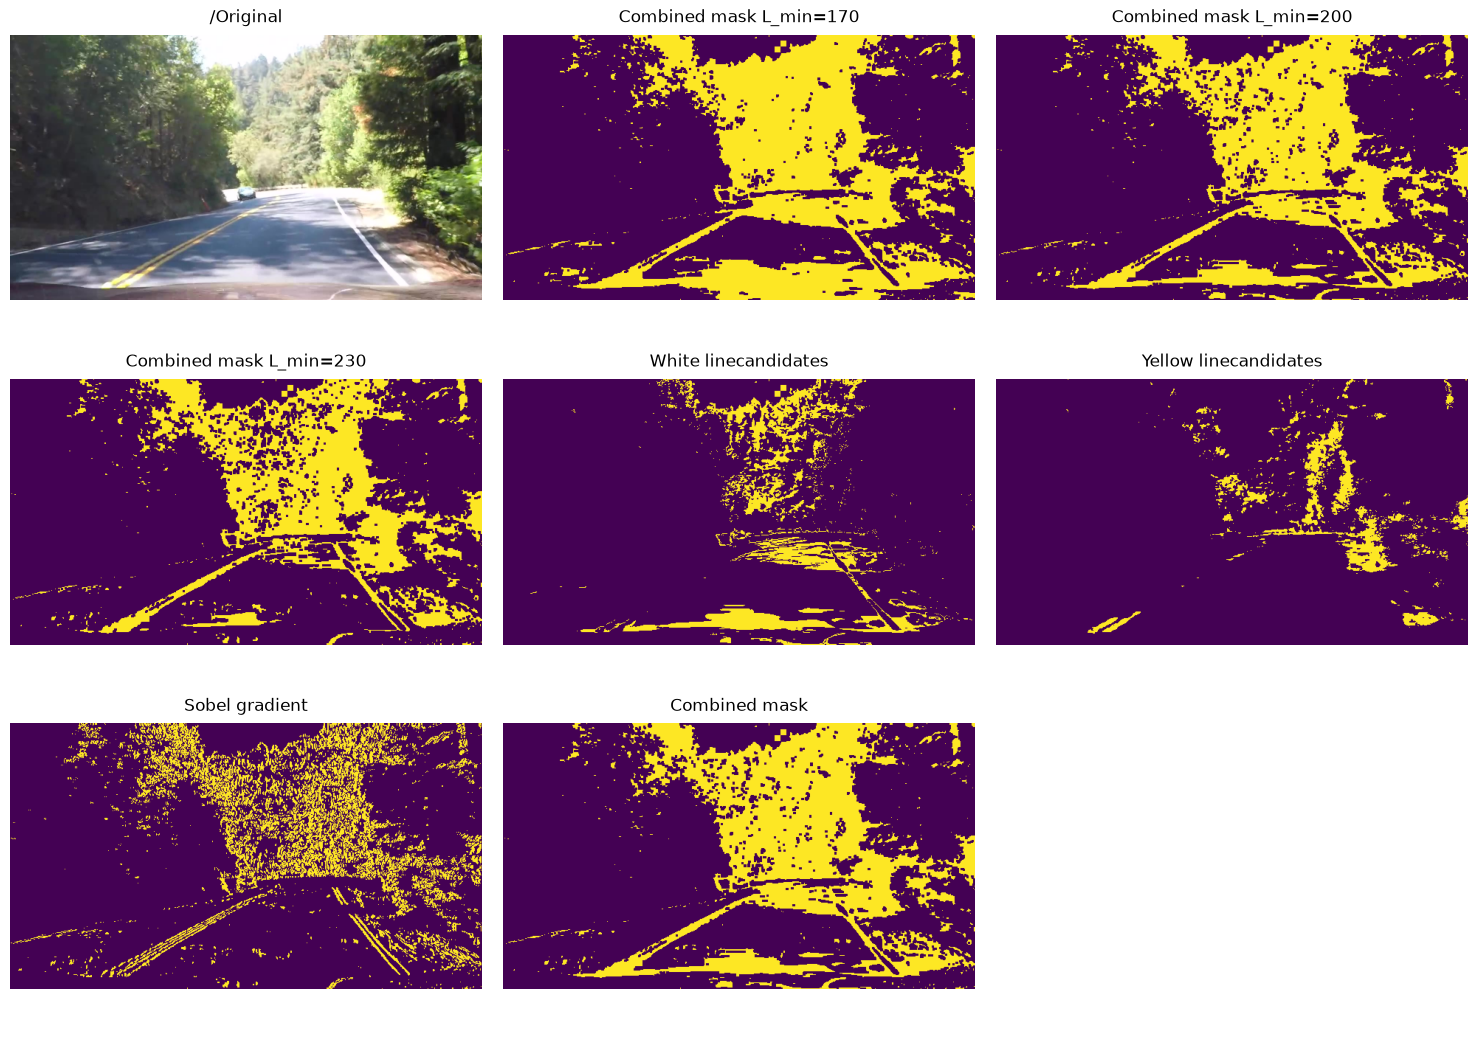

In [8]:
img=read_image('08_harder_shadow_glare.jpg')
results=[('强光/树影原图',img)]
for lum in (170,200,230):
    wm,ym,gm,combo=lane_masks(img,l_min=lum)
    results.append((f'组合掩膜 L_min={lum}',combo))
wm,ym,gm,combo=lane_masks(img,l_min=200)
results.extend([('白线候选',wm),('黄线候选',ym),('Sobel 梯度',gm),('组合掩膜',combo)])
panels(results,cols=4)

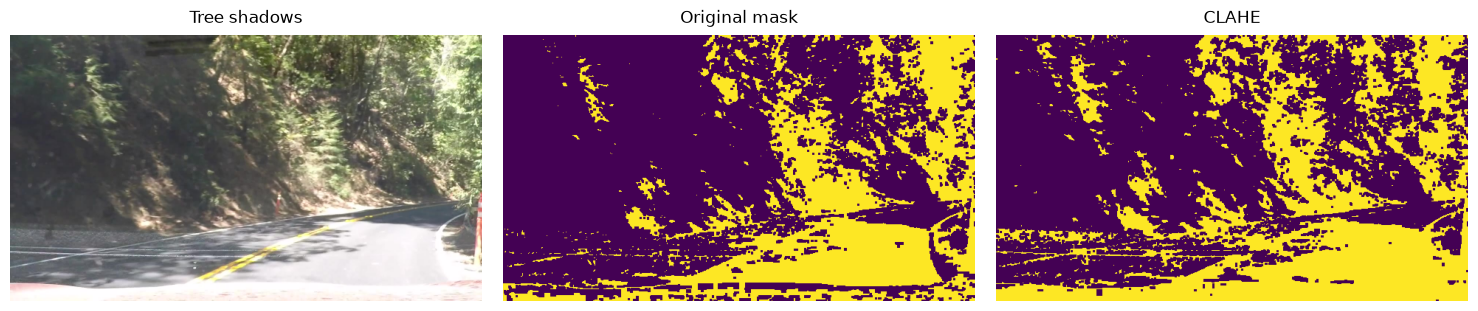

In [9]:
img=read_image('09_harder_curve_shadow.jpg')
base=lane_masks(img,clahe=False)[-1]
strong=lane_masks(img,clahe=True)[-1]
panels([('树影复杂场景',img),('未增强',base),('CLAHE',strong)],cols=3)

## 04 · 探索四：连续帧、时序稳定性与延迟
**先预测：** EMA 系数越小，车道曲线是否总是更准确？
1. 比较 α=1.00、0.60、0.25 对同一帧序列的位置变化。
2. 分析拟合失效时，为什么不能永远沿用上一帧。
3. 区分“位置变化波动”与“有 Ground Truth 的准确率”。

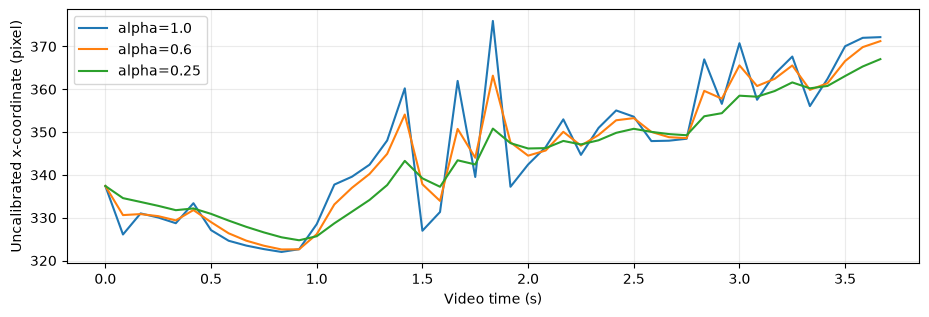

仅为检测输出的连续性对照；不是检测准确率。


In [10]:
# 从真实输入视频提取连续帧，用三种 EMA 系数重跑同一算法。
cap=cv2.VideoCapture(str(DATA/'videos/E03_complex_input.mp4'))
frames=[]
while len(frames)<45:
    ok,f=cap.read()
    if not ok:break
    frames.append(f)
cap.release()
series={}
for alpha in (1.,.6,.25):
    track=LaneTracker(alpha=alpha,max_missing=3)
    scores=[]
    for f in frames:
        _,fit,_=e03_detect(f,'complex',tracker=track)
        scores.append(float(fit['bottom_x']) if fit['bottom_x'] is not None else np.nan)
    series[alpha]=scores
plt.figure(figsize=(11,3.3))
for alpha,values in series.items():plt.plot(np.arange(len(values))/12,values,label=f'alpha={alpha}')
plt.xlabel('Video time (s)');plt.ylabel('Uncalibrated x-coordinate (pixel)');plt.legend();plt.grid(alpha=.25);plt.show()
print('仅为检测输出的连续性对照；不是检测准确率。')

## 05 · 改进探索一：自适应标线提取
**问题：** 固定阈值为什么会在阴影、反光和褪色标线中失效？

1. 对同一鸟瞰图比较 V1.0 固定 HLS 阈值与 V1.1 局部亮度/颜色/梯度组合。
2. 观察自适应阈值是否同时带入路面纹理和护栏噪声。
3. 讨论：候选像素更多，为什么不代表车道线更准确？

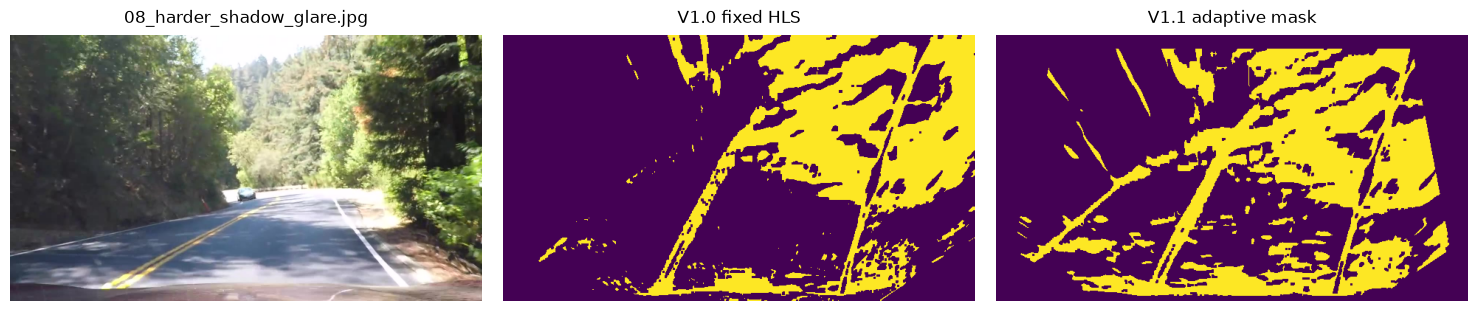

08_harder_shadow_glare.jpg fixed pixels: 62607 adaptive pixels: 69890


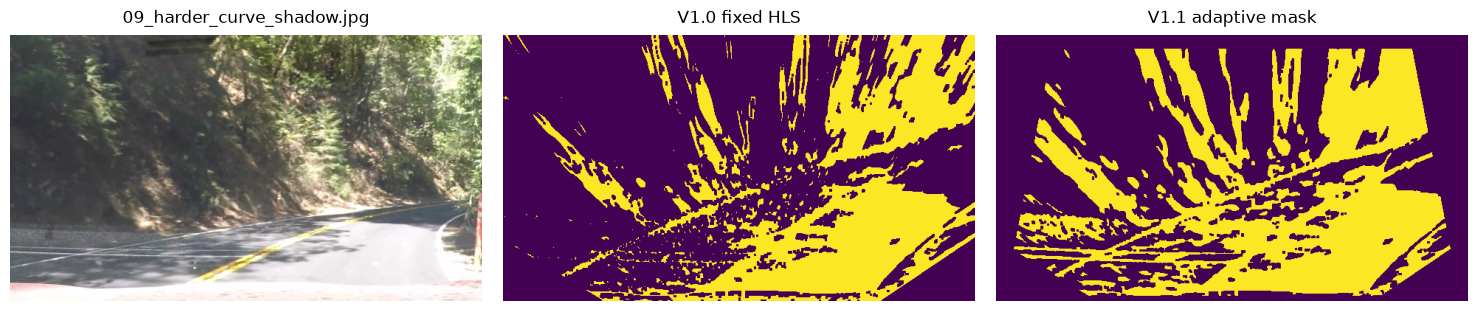

09_harder_curve_shadow.jpg fixed pixels: 72201 adaptive pixels: 87913


In [11]:
for filename in ('08_harder_shadow_glare.jpg','09_harder_curve_shadow.jpg'):
    img=read_image(filename)
    bird,_,_,_=improved_perspective(img,'complex')
    fixed=lane_masks(bird,clahe=False)[-1]
    adaptive=adaptive_lane_mask(bird,clahe=True)
    panels([(filename,img),('V1.0 fixed HLS',fixed),('V1.1 adaptive mask',adaptive)],cols=3)
    print(filename,'fixed pixels:',int(np.count_nonzero(fixed)),
          'adaptive pixels:',int(np.count_nonzero(adaptive)))

## 06 · 改进探索二：RANSAC 与三种曲线模型
**问题：** 二次曲线、三次曲线和自然三次样条，谁更适合复杂弯道？

- 二次曲线：参数少、稳定，但表达能力有限。
- 三次曲线：可以表达一次曲率方向变化，但仍是全局拟合。
- 自然三次样条：按道路局部形状拟合；先按纵向分段取主像素簇，再用样条连接。
- RANSAC：对二次/三次全局模型排除离群像素；样条采用分段主簇与残差筛选，避免用单个三次多项式强行解释完整 S 弯。

**观察重点：** 不只看曲线是否贴合，还要检查是否跨越护栏、邻道或路肩。

quadratic inlier ratio: 0.25 left/right pixels: 32419 29247
cubic inlier ratio: 0.237 left/right pixels: 32419 29247
spline inlier ratio: 0.288 left/right pixels: 32419 29247


/tmp/ipykernel_3882/3077329580.py:151: RankWarning: Polyfit may be poorly conditioned
  coeff = np.polyfit(y[ids], x[ids], degree)
/tmp/ipykernel_3882/3077329580.py:151: RankWarning: Polyfit may be poorly conditioned
  coeff = np.polyfit(y[ids], x[ids], degree)


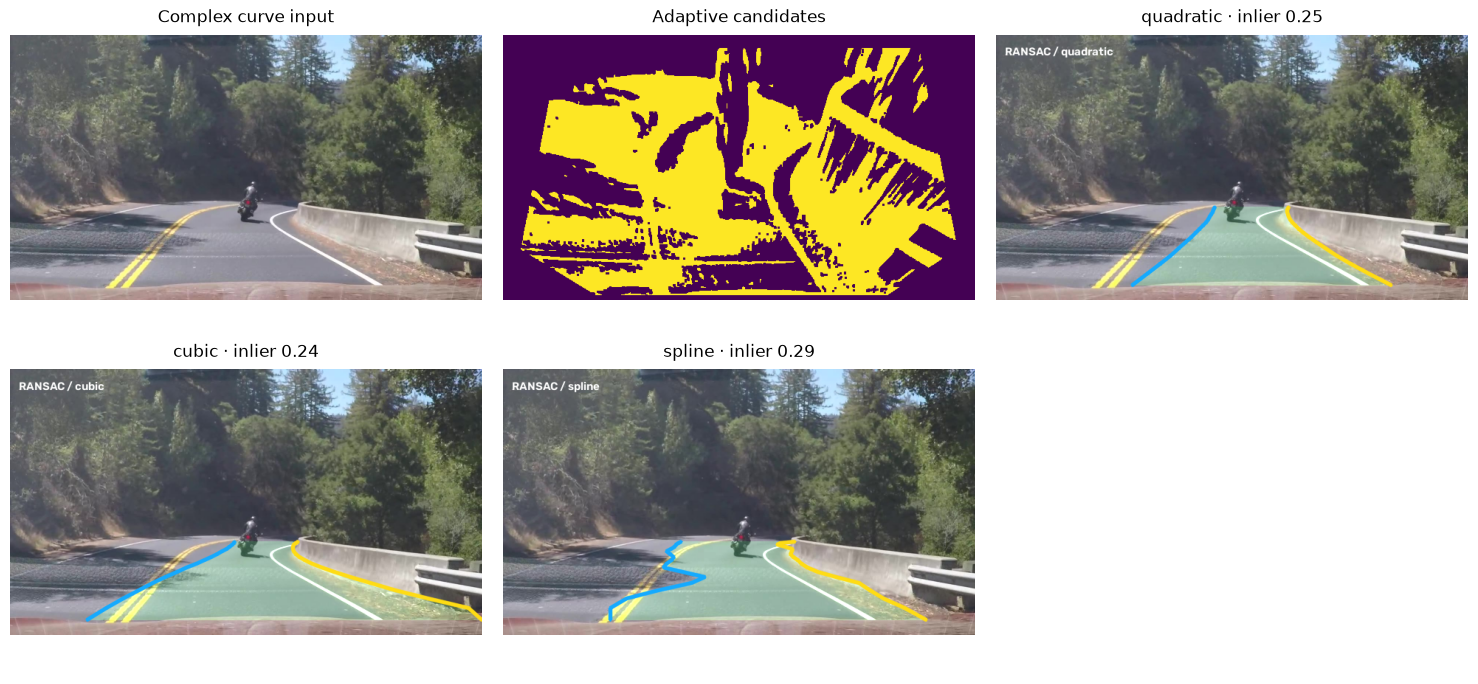

In [12]:
img=read_image('07_harder_curve_motorcycle.jpg')
bird,_,inverse,_=improved_perspective(img,'complex')
mask=adaptive_lane_mask(bird)
points,boxes=_window_search(mask,nwindows=10,margin=72)
results=[('Complex curve input',img),('Adaptive candidates',mask)]
for model in ('quadratic','cubic','spline'):
    fit=fit_pair_from_points(points,model=model)
    if fit is None:
        results.append((model+' · no reliable fit',img.copy()))
        print(model,': no reliable pair')
    else:
        overlay=draw_improved_overlay(img,inverse,CURVE_Y,
                                      fit['left_curve_x'],fit['right_curve_x'],
                                      'RANSAC / '+model)
        results.append((model+' · inlier '+f"{fit['inlier_ratio']:.2f}",overlay))
        print(model,'inlier ratio:',round(fit['inlier_ratio'],3),
              'left/right pixels:',len(points[0]),len(points[1]))
panels(results,cols=3)

## 07 · 改进探索三：动态搜索窗口
**问题：** 每一帧都从直方图重新寻找车道线，为什么容易在急弯和遮挡处跳到错误位置？

1. 第一帧使用滑动窗口建立初始曲线。
2. 后续帧根据上一帧的曲线位置，只在其附近搜索候选像素。
3. 当历史预测不可靠或候选太少时，退回滑动窗口重新初始化。

观察程序输出的 search_mode：sliding 表示重新初始化，prior 表示使用历史曲线引导。历史引导减少搜索范围，但也可能把早先的错误带入下一帧。

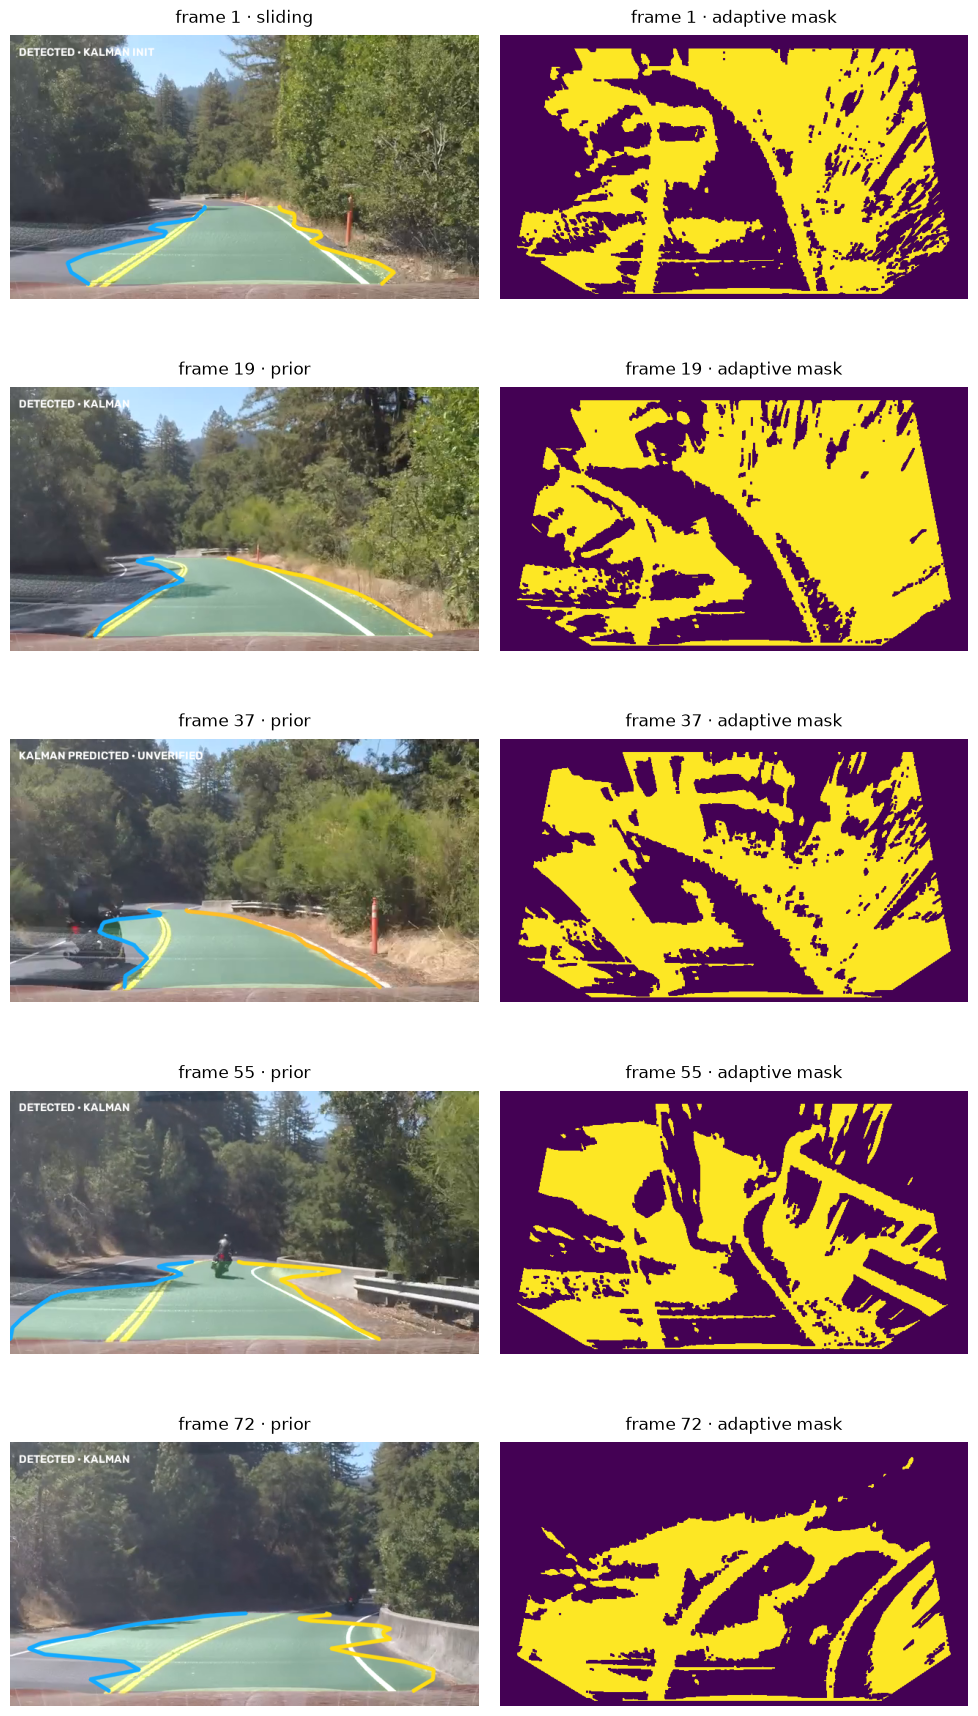

动态搜索统计: {'sliding': 3, 'prior': 69} ；仅说明搜索策略调用次数，不代表准确率。


In [13]:
cap=cv2.VideoCapture(str(DATA/'videos/E03_complex_input.mp4'))
tracker=LaneKalmanTracker(max_missing=4)
samples=[];mode_counts={'sliding':0,'prior':0}
for index in range(72):
    ok,frame=cap.read()
    if not ok:break
    overlay,info,steps=e03_improved_detect(frame,'complex',tracker=tracker,model='spline')
    mode_counts[info.get('search_mode','sliding')]+=1
    if index in (0,18,36,54,71):
        samples.extend([(f'frame {index+1} · {info["search_mode"]}',overlay.copy()),
                        (f'frame {index+1} · adaptive mask',steps['mask'].copy())])
cap.release()
panels(samples,cols=2)
print('动态搜索统计:',mode_counts,'；仅说明搜索策略调用次数，不代表准确率。')

## 08 · 改进探索四：Kalman 跟踪与失效恢复
**问题：** EMA 只平滑位置，Kalman Filter 还可以利用运动状态预测下一帧。

比较同一段复杂弯道视频中的：
- V1.0：二次曲线 + EMA。
- V1.1：鲁棒曲线候选 + Kalman 位置/速度状态。
- 检测失败时：V1.1 最多预测 4 帧，随后明确显示 NO RELIABLE LANE，不无限延续历史结果。

注意：预测帧标记为未验证，不应计入真实检测成功帧。

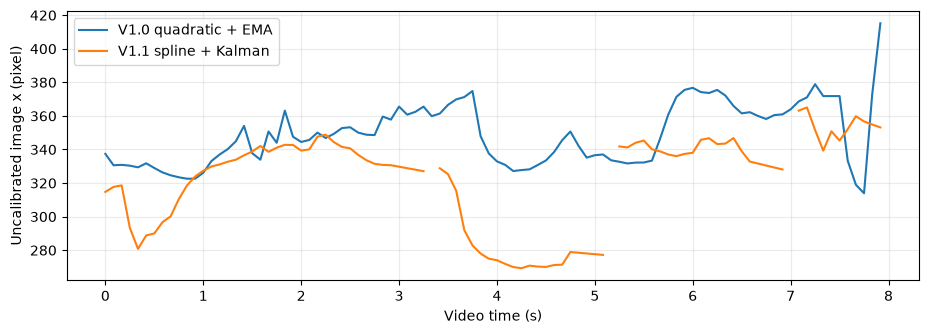

曲线用于比较响应、抖动和失效区间；不是人工标注误差。


In [14]:
cap=cv2.VideoCapture(str(DATA/'videos/E03_complex_input.mp4'))
baseline_tracker=LaneTracker(alpha=.6,max_missing=3)
kalman_tracker=LaneKalmanTracker(max_missing=4)
baseline_x=[];kalman_x=[];times=[]
fps=cap.get(cv2.CAP_PROP_FPS) or 12.
for index in range(96):
    ok,frame=cap.read()
    if not ok:break
    _,base_info,_=e03_detect(frame,'complex',tracker=baseline_tracker)
    _,new_info,_=e03_improved_detect(frame,'complex',tracker=kalman_tracker,model='spline')
    baseline_x.append(base_info.get('bottom_x') if base_info.get('bottom_x') is not None else np.nan)
    kalman_x.append(new_info.get('bottom_x') if new_info.get('bottom_x') is not None else np.nan)
    times.append(index/fps)
cap.release()
plt.figure(figsize=(11,3.5))
plt.plot(times,baseline_x,label='V1.0 quadratic + EMA')
plt.plot(times,kalman_x,label='V1.1 spline + Kalman')
plt.xlabel('Video time (s)');plt.ylabel('Uncalibrated image x (pixel)')
plt.legend();plt.grid(alpha=.25);plt.show()
print('曲线用于比较响应、抖动和失效区间；不是人工标注误差。')

## 09 · 三场景综合挑战：V1.0 Baseline × V1.1 Improved
每段视频同步生成四列：**原始画面 / E02 Canny-Hough / V1.0 二次曲线+EMA / V1.1 鲁棒样条+动态搜索+Kalman**。  
同一源帧、同一场景参数，便于观察改进与退化。直道用于检查是否损害原有能力；普通弯道检查跟随能力；复杂弯道重点观察 S 形变化、阴影、遮挡、错误延续和重新捕获。  
V1.1 输出的逐帧轨迹另存为 E03_tracks_v1_1.json，浏览器实验会同时展示两个版本。

In [15]:
from pathlib import Path
from IPython.display import Video,display
import shutil,subprocess,json
ffmpeg=shutil.which('ffmpeg')
if not ffmpeg:
    import imageio_ffmpeg
    ffmpeg=imageio_ffmpeg.get_ffmpeg_exe()
summary={}
tracks={'version':'1.1','scenes':{}}
for scene,label in [('straight','直道'),('curve','普通弯道'),('complex','复杂连续弯道')]:
    cap=cv2.VideoCapture(str(DATA/'videos'/f'E03_{scene}_input.mp4'))
    if not cap.isOpened():raise RuntimeError(f'无法读取 {scene}')
    fps=cap.get(cv2.CAP_PROP_FPS) or 12.
    ok,first=cap.read()
    if not ok:raise RuntimeError('视频为空: '+scene)
    h,w=first.shape[:2]
    rawpath=OUTPUT/f'raw_v11_{scene}.mp4'
    writer=cv2.VideoWriter(str(rawpath),cv2.VideoWriter_fourcc(*'mp4v'),fps,(4*480,270))
    if not writer.isOpened():raise RuntimeError('OpenCV mp4v encoder unavailable')
    cap.set(cv2.CAP_PROP_POS_FRAMES,0)
    baseline_tracker=LaneTracker(alpha=.6,max_missing=3)
    improved_tracker=LaneKalmanTracker(max_missing=4)
    baseline_frames=[];improved_frames=[]
    valid_baseline=valid_improved=display_improved=prior_count=0
    inlier_ratios=[]
    track_scene={'fps':float(fps),'width':int(w),'height':int(h),
                 'Minv':None,'probes':PROBE_Y.tolist(),'curve_y':CURVE_Y.tolist(),
                 'frames':baseline_frames,'improved_frames':improved_frames,
                 'improved_model':'adaptive mask + dominant-cluster spline + prior search + Kalman'}
    while True:
        ok,frame=cap.read()
        if not ok:break
        raw=resized(frame)
        old,n,_=e02_hough(raw)
        baseline,base_info,base_steps=e03_detect(raw,scene,tracker=baseline_tracker)
        improved,new_info,new_steps=e03_improved_detect(
            raw,scene,tracker=improved_tracker,model='spline'
        )
        track_scene['Minv']=np.asarray(new_steps['inverse'],dtype=float).tolist()
        pieces=[]
        for picture,name in [
            (raw,'Raw input'),
            (old,'E02 Canny + Hough'),
            (baseline,'V1.0 quadratic + EMA'),
            (improved,'V1.1 robust spline + prior + Kalman')
        ]:
            panel=cv2.resize(picture,(480,270),interpolation=cv2.INTER_AREA)
            cv2.rectangle(panel,(0,0),(480,26),(18,34,48),-1)
            cv2.putText(panel,name,(8,19),cv2.FONT_HERSHEY_SIMPLEX,.43,(255,255,255),1,cv2.LINE_AA)
            pieces.append(panel)
        writer.write(np.hstack(pieces))
        frame_time=round(len(baseline_frames)/fps,3)
        baseline_valid=bool(base_info.get('valid'))
        improved_valid=bool(new_info.get('valid'))
        improved_display=bool(new_info.get('display_valid'))
        valid_baseline+=int(baseline_valid)
        valid_improved+=int(improved_valid)
        display_improved+=int(improved_display)
        prior_count+=int(new_info.get('search_mode')=='prior')
        if new_info.get('inlier_ratio') is not None:
            inlier_ratios.append(float(new_info['inlier_ratio']))
        baseline_frames.append({
            'time':frame_time,'valid':baseline_valid,'status':base_info.get('status'),
            'left_x':np.asarray(base_info['left_x'],dtype=float).tolist() if baseline_valid else None,
            'right_x':np.asarray(base_info['right_x'],dtype=float).tolist() if baseline_valid else None,
            'bottom_x':base_info.get('bottom_x')
        })
        improved_frames.append({
            'time':frame_time,'valid':improved_valid,'display_valid':improved_display,
            'status':new_info.get('status'),'search_mode':new_info.get('search_mode'),
            'model':new_info.get('model','spline'),'inlier_ratio':new_info.get('inlier_ratio'),
            'curve_y':new_info.get('curve_y'),
            'left_curve_x':new_info.get('left_curve_x'),
            'right_curve_x':new_info.get('right_curve_x'),
            'bottom_x':new_info.get('bottom_x')
        })
    cap.release();writer.release()
    filename=OUTPUT/f'E03_v1_1_{scene}_compare.mp4'
    subprocess.run([ffmpeg,'-y','-hide_banner','-loglevel','error','-i',str(rawpath),
                    '-an','-c:v','libx264','-pix_fmt','yuv420p','-preset','veryfast',
                    '-crf','27','-movflags','+faststart',str(filename)],check=True)
    rawpath.unlink()
    summary[scene]={
        'frames':len(baseline_frames),'baseline_valid':valid_baseline,
        'improved_valid':valid_improved,'improved_display':display_improved,
        'prior_search_frames':prior_count,
        'median_inlier_ratio':float(np.median(inlier_ratios)) if inlier_ratios else None
    }
    tracks['scenes'][scene]=track_scene
    print(f'{label}: {len(baseline_frames)} frames; V1.0 valid {valid_baseline}; '
          f'V1.1 valid {valid_improved}; V1.1 display {display_improved}; '
          f'prior search {prior_count}; median inlier ratio '
          f'{summary[scene]["median_inlier_ratio"]}')
    display(Video(filename=str(filename),embed=False,width=960))
(OUTPUT/'E03_tracks_v1_1.json').write_text(
    json.dumps(tracks,ensure_ascii=False,separators=(',',':')),encoding='utf-8')
(OUTPUT/'E03_diagnostics_v1_1.json').write_text(
    json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')

直道: 102 frames; V1.0 valid 102; V1.1 valid 102; V1.1 display 102; prior search 101; median inlier ratio 0.9322739845849379


普通弯道: 156 frames; V1.0 valid 156; V1.1 valid 156; V1.1 display 156; prior search 155; median inlier ratio 0.7794887122671275


复杂连续弯道: 180 frames; V1.0 valid 176; V1.1 valid 144; V1.1 display 174; prior search 173; median inlier ratio 0.41615084064224594


602

## 10 · 综合观察、评价与改进边界
- 哪个场景中 V1.1 比 V1.0 更好？是否存在 V1.1 更差的帧？
- S 形道路上，二次曲线、三次曲线和样条曲线各自的表达能力与过拟合风险是什么？
- RANSAC 和分段主像素簇分别解决什么问题？错误候选是否仍会进入拟合？
- 动态搜索是否可能沿着错误的上一帧继续跟踪？何时必须重新初始化？
- Kalman 预测帧为什么必须标记为未验证？预测帧是否应计入有效检测率？
- 没有人工标注时，为什么不能仅凭有效帧比例或视频观感宣称准确率？
- 设计一组小规模人工标注帧，计算左右车道线横向误差、误检率和漏检率。